<div
  style="
    background-color: #f0f0f0;
    color:rgb(56, 56, 56);
    padding: 8px;
    display: flex;
    align-items: center;
    gap: 100px;
  "
>
  <img src="./images/brand.svg" style="max-height: 80px;">
  <strong>
    AI Saga: Data Science and Machine Learning</br>
    2.lab.1. Wisconsin Cancer Classification
  </strong>
</div>

### Background

You will continue working with the Wisconsin Diagnostic Cancer Dataset, but this time implementing classification models using scikit-learn.

The dataset includes:
- 569 instances
- 30 numeric features computed from the cell nuclei present in the image
- Binary classification: **Malignant** or **Benign** diagnosis

### Description

Your task is to implement logistic regression using scikit-learn to:

- Implement logistic regression using all features
- Find the best performing pair of features for classification
- Compare the accuracy between using all features vs. the best pair
- Visualize the decision boundary for the best feature pair

### Deliverables

- A **ipynb** (Jupyter Notebook) file called **wisconsin-cancer-classification.ipynb**
- The notebook should include visualizations of the decision boundaries
- A clear comparison of performance between using all features vs. the best pair
- Use the provided template as a starting point

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rich.table import Table
from rich.console import Console

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

Visual configuration of Seaborn for more attractive graphics

In [2]:
sns.set_theme(style="whitegrid", palette="muted")
sns.set_context("notebook", font_scale=1.2)

Rich console instance to display results

In [3]:
console = Console()

### Reading Dataset

In [4]:
from sklearn.datasets import load_breast_cancer

breast_cancer = load_breast_cancer(as_frame=True)

X = breast_cancer.data
y = breast_cancer.target
target_names = breast_cancer.target_names

diagnosis_labels = breast_cancer.target.map({0: target_names[0], 1: target_names[1]})

In [5]:
table = Table(title="Data set information")

table.add_column("Description", style="cyan")
table.add_column("Value", style="green")

table.add_row("Number of features", str(X.shape[1]))
table.add_row("Number of samples", str(X.shape[0]))

console.print(table)
X.head()

     Data set information     
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Description        ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ Number of features │ 30    │
│ Number of samples  │ 569   │
└────────────────────┴───────┘

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Distribution of classes

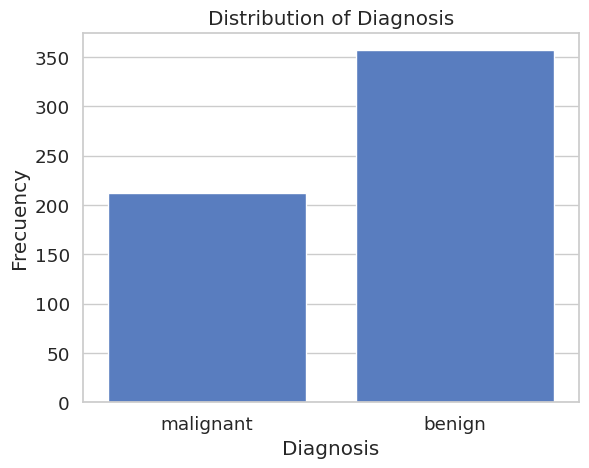

In [6]:
sns.countplot(x=diagnosis_labels)
plt.xlabel("Diagnosis")
plt.ylabel("Frecuency")
plt.title("Distribution of Diagnosis")
plt.show()

### Processing of data

Split the data into training and testing sets

In [7]:
columns_to_evaluate = [
    "mean radius",
    "mean texture",
    "mean smoothness",
    "mean compactness",
    "mean concavity",
    "mean concave points",
    "mean symmetry",
]

X = X[columns_to_evaluate]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Standardize features

In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Method to train a model

In [9]:
def train_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    return acc, y_pred

## 1. Train and evaluate model with all features

In [10]:
model_all_features = LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000)

all_features_accuracy, y_pred_all_features = train_model(
    model_all_features, X_train, y_train, X_test, y_test
)

console.print(f"Accuracy: {all_features_accuracy :.3f}")

Accuracy: 0.939

## 2. Train and evaluate model with the best pair

In [11]:
from sklearn.base import clone

base_model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000)

best_pair = []
best_pair_accuracy = 0
model_best_pair = None
y_pred_best_pair = []

amount_features = X.shape[1]

for i in range(amount_features):
    for j in range(i + 1, amount_features):
        X_train_pair = X_train[:, [i, j]]
        X_test_pair = X_test[:, [i, j]]

        model = clone(base_model)
        accuracy_pair, y_pred_pair = train_model(
            model, X_train_pair, y_train, X_test_pair, y_test
        )

        if accuracy_pair > best_pair_accuracy:
            y_pred_best_pair = y_pred_pair
            best_pair_accuracy = accuracy_pair
            best_pair = (i, j)
            model_best_pair = model

best_pair_names = X.columns[list(best_pair)]

table = Table(title="Best Feature Pair")

table.add_column("Feature 1", style="cyan")
table.add_column("Feature 2", style="cyan")
table.add_column("Accuracy (%)", style="green", justify="right")

table.add_row(best_pair_names[0], best_pair_names[1], f"{best_pair_accuracy * 100:.3f}")

console.print(table)

               Best Feature Pair               
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Feature 1   ┃ Feature 2      ┃ Accuracy (%) ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ mean radius │ mean concavity │       95.614 │
└─────────────┴────────────────┴──────────────┘

## 3. Best feature pair vs all features accuracy

In [12]:
from rich.table import Table

table = Table(title="Accuracy Comparison")

table.add_column("Model", style="cyan")
table.add_column("Accuracy (%)", style="green", justify="right")

table.add_row("All Features", f"{all_features_accuracy * 100:.2f}")
table.add_row("Best Pair", f"{best_pair_accuracy * 100:.3f}")
table.add_row("Difference", f"{(all_features_accuracy - best_pair_accuracy) * 100:.3f}")

console.print(table)

if all_features_accuracy > best_pair_accuracy:
    console.print("[bold green]The model with all features is better")
else:
    console.print("[bold green]The model with the best pair is better")

      Accuracy Comparison      
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Model        ┃ Accuracy (%) ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ All Features │        93.86 │
│ Best Pair    │       95.614 │
│ Difference   │       -1.754 │
└──────────────┴──────────────┘

The model with the best pair is better

## 4. Boundary decision graph

In [13]:
def plot_decision_boundary(
    X, y, w, b, feature_names, target_names, title="Decision boundary"
):
    x_values = np.array([min(X[:, 0]) - 1, max(X[:, 0]) + 1])
    y_values = -(b + w[0] * x_values) / w[1]

    plt.figure(figsize=(8, 6))
    plt.scatter(X[y == 0, 0], X[y == 0, 1], color="blue", label=target_names[0])
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color="red", label=target_names[1])
    plt.plot(x_values, y_values, color="green", linewidth=2, label="Decision Boundary")

    plt.xlabel(f"Feature {feature_names[0]}")
    plt.ylabel(f"Feature {feature_names[1]}")
    plt.legend()
    plt.title(title)
    plt.show()

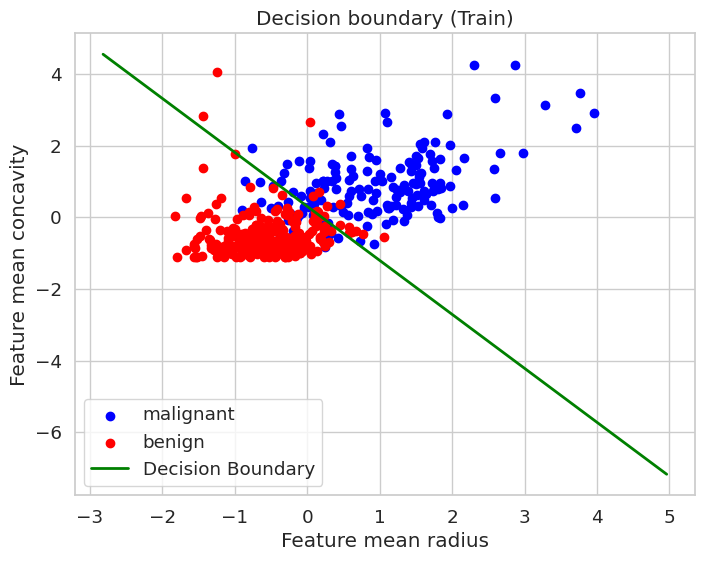

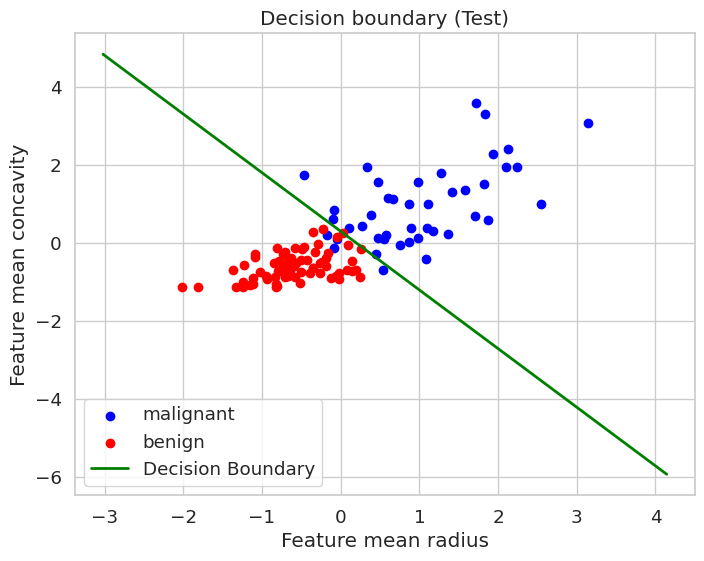

In [14]:
X_train_best = X_train[:, best_pair]
X_test_best = X_test[:, best_pair]

w = model_best_pair.coef_[0]
b = model_best_pair.intercept_[0]

plot_decision_boundary(
    X_train_best,
    y_train,
    w,
    b,
    best_pair_names,
    target_names,
    title="Decision boundary (Train)",
)

plot_decision_boundary(
    X_test_best,
    y_test,
    w,
    b,
    best_pair_names,
    target_names,
    title="Decision boundary (Test)",
)

## 5. Confusion Matrix

In [15]:
def plot_confusion_matrix(cm, title, ax):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names,
        ax=ax,
    )
    ax.set_title(title)

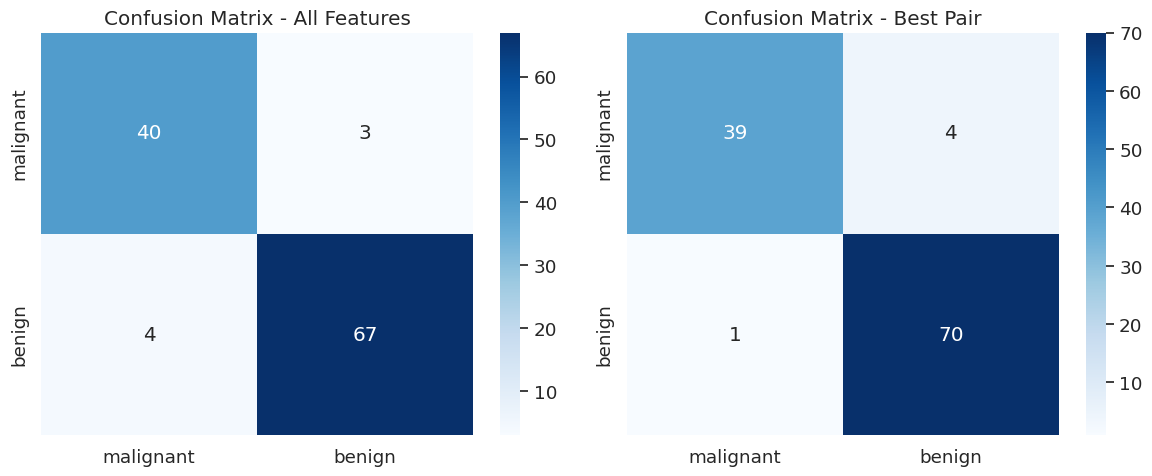

In [16]:
cm_all_features = confusion_matrix(y_test, y_pred_all_features)
cm_best_pair = confusion_matrix(y_test, y_pred_best_pair)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_confusion_matrix(cm_all_features, "Confusion Matrix - All Features", axes[0])

plot_confusion_matrix(cm_best_pair, "Confusion Matrix - Best Pair", axes[1])

plt.tight_layout()
plt.show()

When comparing the model trained with all features to the one using the best pair, we see some differences in the results with the test data:

- **True negatives:** The model with all features had 40, while the model with the best pair had 39. There is a small difference in favor of the model with all features.
- **True positives:** The model with all features had 67, and the model with the best pair had 70. Here, the model with the best pair has a slight advantage.
- **False positives:** The model with all features had 3, while the model with the best pair had 4. There is a small difference in favor of the model with all features.
- **False negatives:** The model with all features had 4, and the model with the best pair had 1. The model with the best pair has a clear advantage here.